<div align="center">

#### **PEMBUATAN RECIPE UNTUK STUDI KASUS METODE ELECTRICAL RESISTIVITY TOMOGRAPHY (ERT)**

#### **KECERDASAN ARTIFISIAL GEOFISIKA**



#### **SERILIA ABUNG**

#### **H061241034**

#### **DEPARTEMEN GEOFISIKA**

#### **FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**

#### **UNIVERSITAS HASANUDDIN**

![Screenshot 2026-10-20 230836.png](<attachment:Screenshot 2026-10-20 230836.png>)
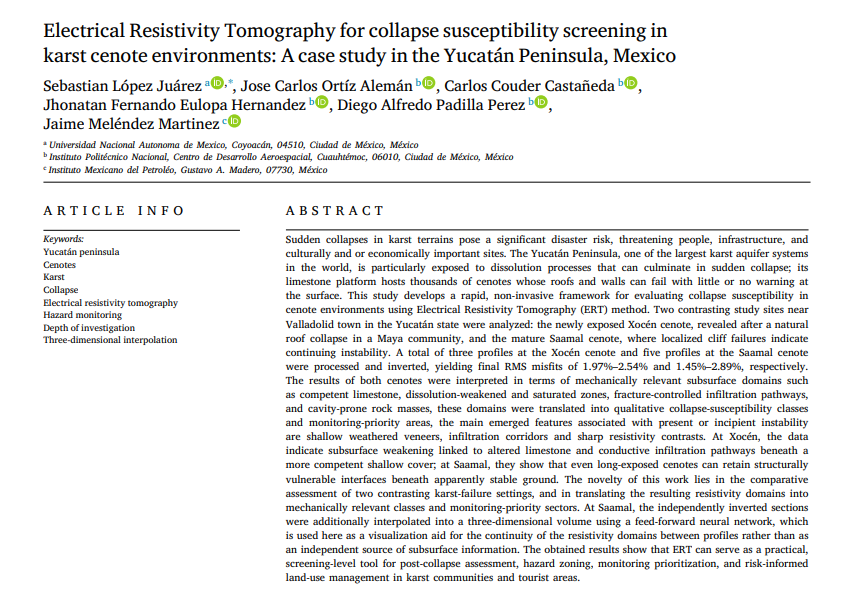

Studi kasus ini mengacu pada artikel ilmiah Electrical Resistivity Tomography for collapse susceptibility screening in karst cenote environments: A case study in the Yucatán Peninsula, Mexico yang membahas penggunaan metode Electrical Resistivity Tomography (ERT) untuk mengidentifikasi kerentanan runtuhan pada lingkungan karst di Semenanjung Yucatán, Meksiko. Penelitian tersebut dilakukan pada dua lokasi, yaitu cenote Xocén dan cenote Saamal, di sekitar Valladolid. Cenote Xocén dikaji setelah terjadinya runtuhan atap alami, sedangkan Saamal merupakan cenote yang masih terbuka dengan indikasi ketidakstabilan lokal. Metode ERT digunakan untuk memetakan variasi resistivitas bawah permukaan guna mengidentifikasi zona batu gamping yang relatif kompeten, zona yang mengalami pelarutan, jalur infiltrasi air, serta kemungkinan adanya pelemahan struktur bawah permukaan. Abstrak artikel melaporkan rentang resistivitas sebesar 1,97–2,54 kΩm untuk Xocén dan 1,45–2,89 kΩm untuk Saamal. Informasi tersebut dapat digunakan untuk menyusun demonstrasi komputasi ERT, tetapi karena data pengukuran mentah dan hasil inversi asli tidak tersedia dalam gambar artikel, kode berikut menggunakan data sintetis dengan rentang yang mengacu pada artikel, bukan mereproduksi hasil inversi lapangan yang sebenarnya.

HASIL PERHITUNGAN RESISTIVITAS SINTETIS
Xocén: minimum = 1997.5 Ωm, maksimum = 2397.5 Ωm, rata-rata = 2238.6 Ωm
Saamal: minimum = 1640.7 Ωm, maksimum = 2656.3 Ωm, rata-rata = 2196.3 Ωm


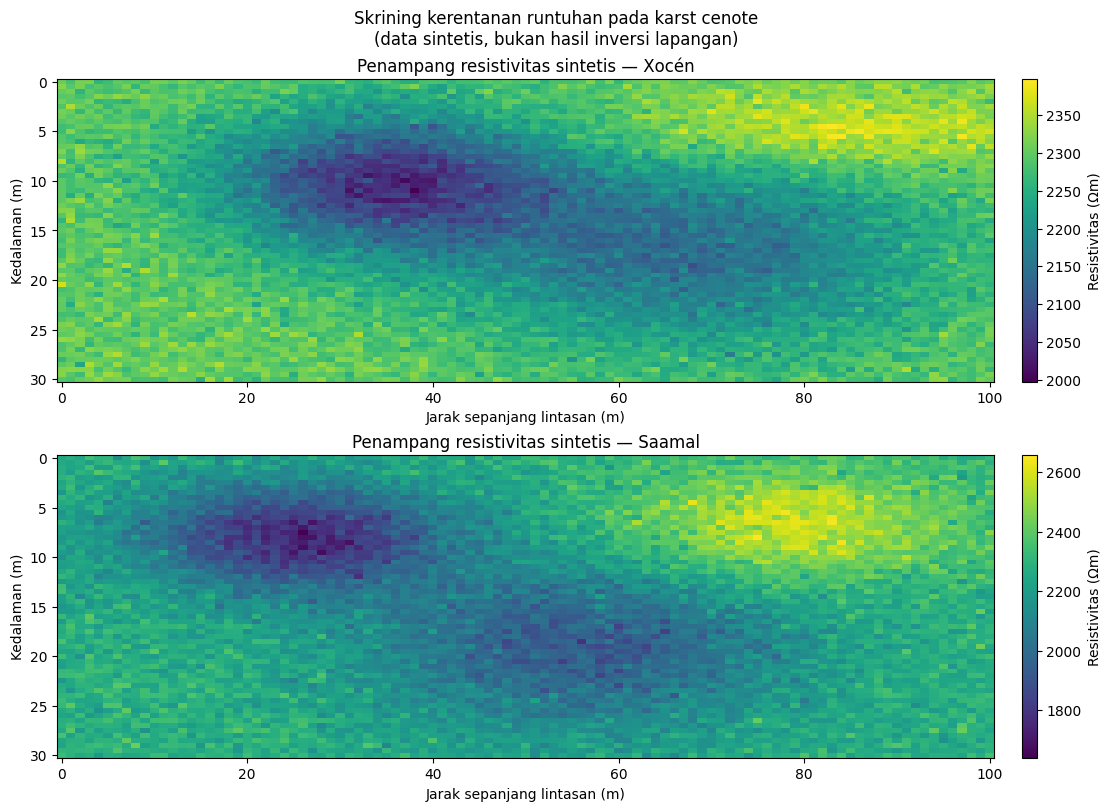

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Grid model: jarak 0-100 m dan kedalaman 0-30 m
rng = np.random.default_rng(42)

x = np.linspace(0, 100, 101)
z = np.linspace(0, 30, 61)
X, Z = np.meshgrid(x, z)


def gaussian2d(X, Z, x0, z0, sx, sz):
    """Membuat anomali Gaussian dua dimensi."""
    return np.exp(
        -0.5 * (
            ((X - x0) / sx) ** 2
            + ((Z - z0) / sz) ** 2
        )
    )


def make_profile(site, vmin, vmax):
    """Membuat penampang resistivitas sintetis."""
    base = 0.58 * vmax + 0.42 * vmin
    rho = np.full_like(X, base, dtype=float)

    if site == "Xocén":
        rho -= 0.42 * (vmax - vmin) * gaussian2d(
            X, Z, 35, 10, 13, 5
        )
        rho -= 0.28 * (vmax - vmin) * gaussian2d(
            X, Z, 68, 17, 18, 7
        )
        rho += 0.15 * (vmax - vmin) * gaussian2d(
            X, Z, 82, 5, 17, 3
        )
    else:
        rho -= 0.36 * (vmax - vmin) * gaussian2d(
            X, Z, 25, 8, 12, 4
        )
        rho -= 0.25 * (vmax - vmin) * gaussian2d(
            X, Z, 56, 19, 16, 6
        )
        rho += 0.22 * (vmax - vmin) * gaussian2d(
            X, Z, 78, 7, 12, 4
        )

    # Heterogenitas sintetis
    rho += rng.normal(
        0, 0.035 * (vmax - vmin), size=rho.shape
    )

    return np.clip(rho, vmin, vmax)


# Rentang dari abstrak artikel, dikonversi menjadi ohm-meter
profiles = {
    "Xocén": make_profile("Xocén", 1970, 2540),
    "Saamal": make_profile("Saamal", 1450, 2890),
}

# Perhitungan statistik
print("HASIL PERHITUNGAN RESISTIVITAS SINTETIS")
for site, rho in profiles.items():
    print(
        f"{site}: minimum = {rho.min():.1f} Ωm, "
        f"maksimum = {rho.max():.1f} Ωm, "
        f"rata-rata = {rho.mean():.1f} Ωm"
    )

# Plot penampang resistivitas 2D
fig, axes = plt.subplots(
    2, 1, figsize=(11, 8), constrained_layout=True
)

for ax, (site, rho) in zip(axes, profiles.items()):
    image = ax.pcolormesh(
        X, Z, rho, shading="auto", cmap="viridis"
    )
    ax.invert_yaxis()
    ax.set_title(f"Penampang resistivitas sintetis — {site}")
    ax.set_xlabel("Jarak sepanjang lintasan (m)")
    ax.set_ylabel("Kedalaman (m)")

    cbar = fig.colorbar(image, ax=ax, pad=0.02)
    cbar.set_label("Resistivitas (Ωm)")

fig.suptitle(
    "Skrining kerentanan runtuhan pada karst cenote\n"
    "(data sintetis, bukan hasil inversi lapangan)"
)

fig.savefig(
    "hasil_plot_ert_karst.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

**Analisis hasil gambar**

Berdasarkan gambar penampang resistivitas sintetis, lokasi Xocén memperlihatkan zona resistivitas relatif rendah yang berpusat di sekitar jarak 35 m pada kedalaman 10 m serta zona lain di sekitar jarak 68 m pada kedalaman 17 m, sedangkan Saamal menunjukkan variasi resistivitas yang lebih lebar, dengan zona relatif rendah di sekitar jarak 25 m pada kedalaman 8 m dan jarak 56 m pada kedalaman 19 m. Zona beresistivitas relatif tinggi juga tampak pada bagian dangkal tertentu, yang dalam model ini digunakan untuk menggambarkan batu gamping yang relatif resisif. Nilai resistivitas rata-rata sintetis Xocén sebesar 2.238,6 Ωm dan Saamal sebesar 2.196,3 Ωm, sehingga rata-rata Xocén sedikit lebih tinggi, sementara Saamal memiliki rentang variasi yang lebih lebar. Secara konseptual, anomali resistivitas dapat membantu mengidentifikasi bagian bawah permukaan yang perlu diteliti lebih lanjut karena perubahan resistivitas dapat berkaitan dengan kandungan air, pelarutan, rekahan, dan kondisi material batuan. Namun, zona resistivitas rendah tidak otomatis berarti zona rawan runtuhan, sebab interpretasinya harus mempertimbangkan kondisi geologi, konfigurasi elektroda, hasil inversi, serta bukti lapangan. Karena penampang ini dibuat menggunakan data sintetis, lokasi anomali pada gambar tidak boleh dianggap sebagai lokasi kerentanan aktual di Xocén maupun Saamal.